In [30]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import svm
import warnings
from sklearn.metrics import accuracy_score
%matplotlib inline 

In [31]:
park_df=pd.read_csv('parkinsons.csv')

In [32]:
park_df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [33]:
park_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 1

In [34]:
park_df['status'].value_counts()

status
1    147
0     48
Name: count, dtype: int64

In [35]:
park_df.groupby('status').mean

<bound method GroupBy.mean of <pandas.core.groupby.generic.DataFrameGroupBy object at 0x000001C8130AB1D0>>

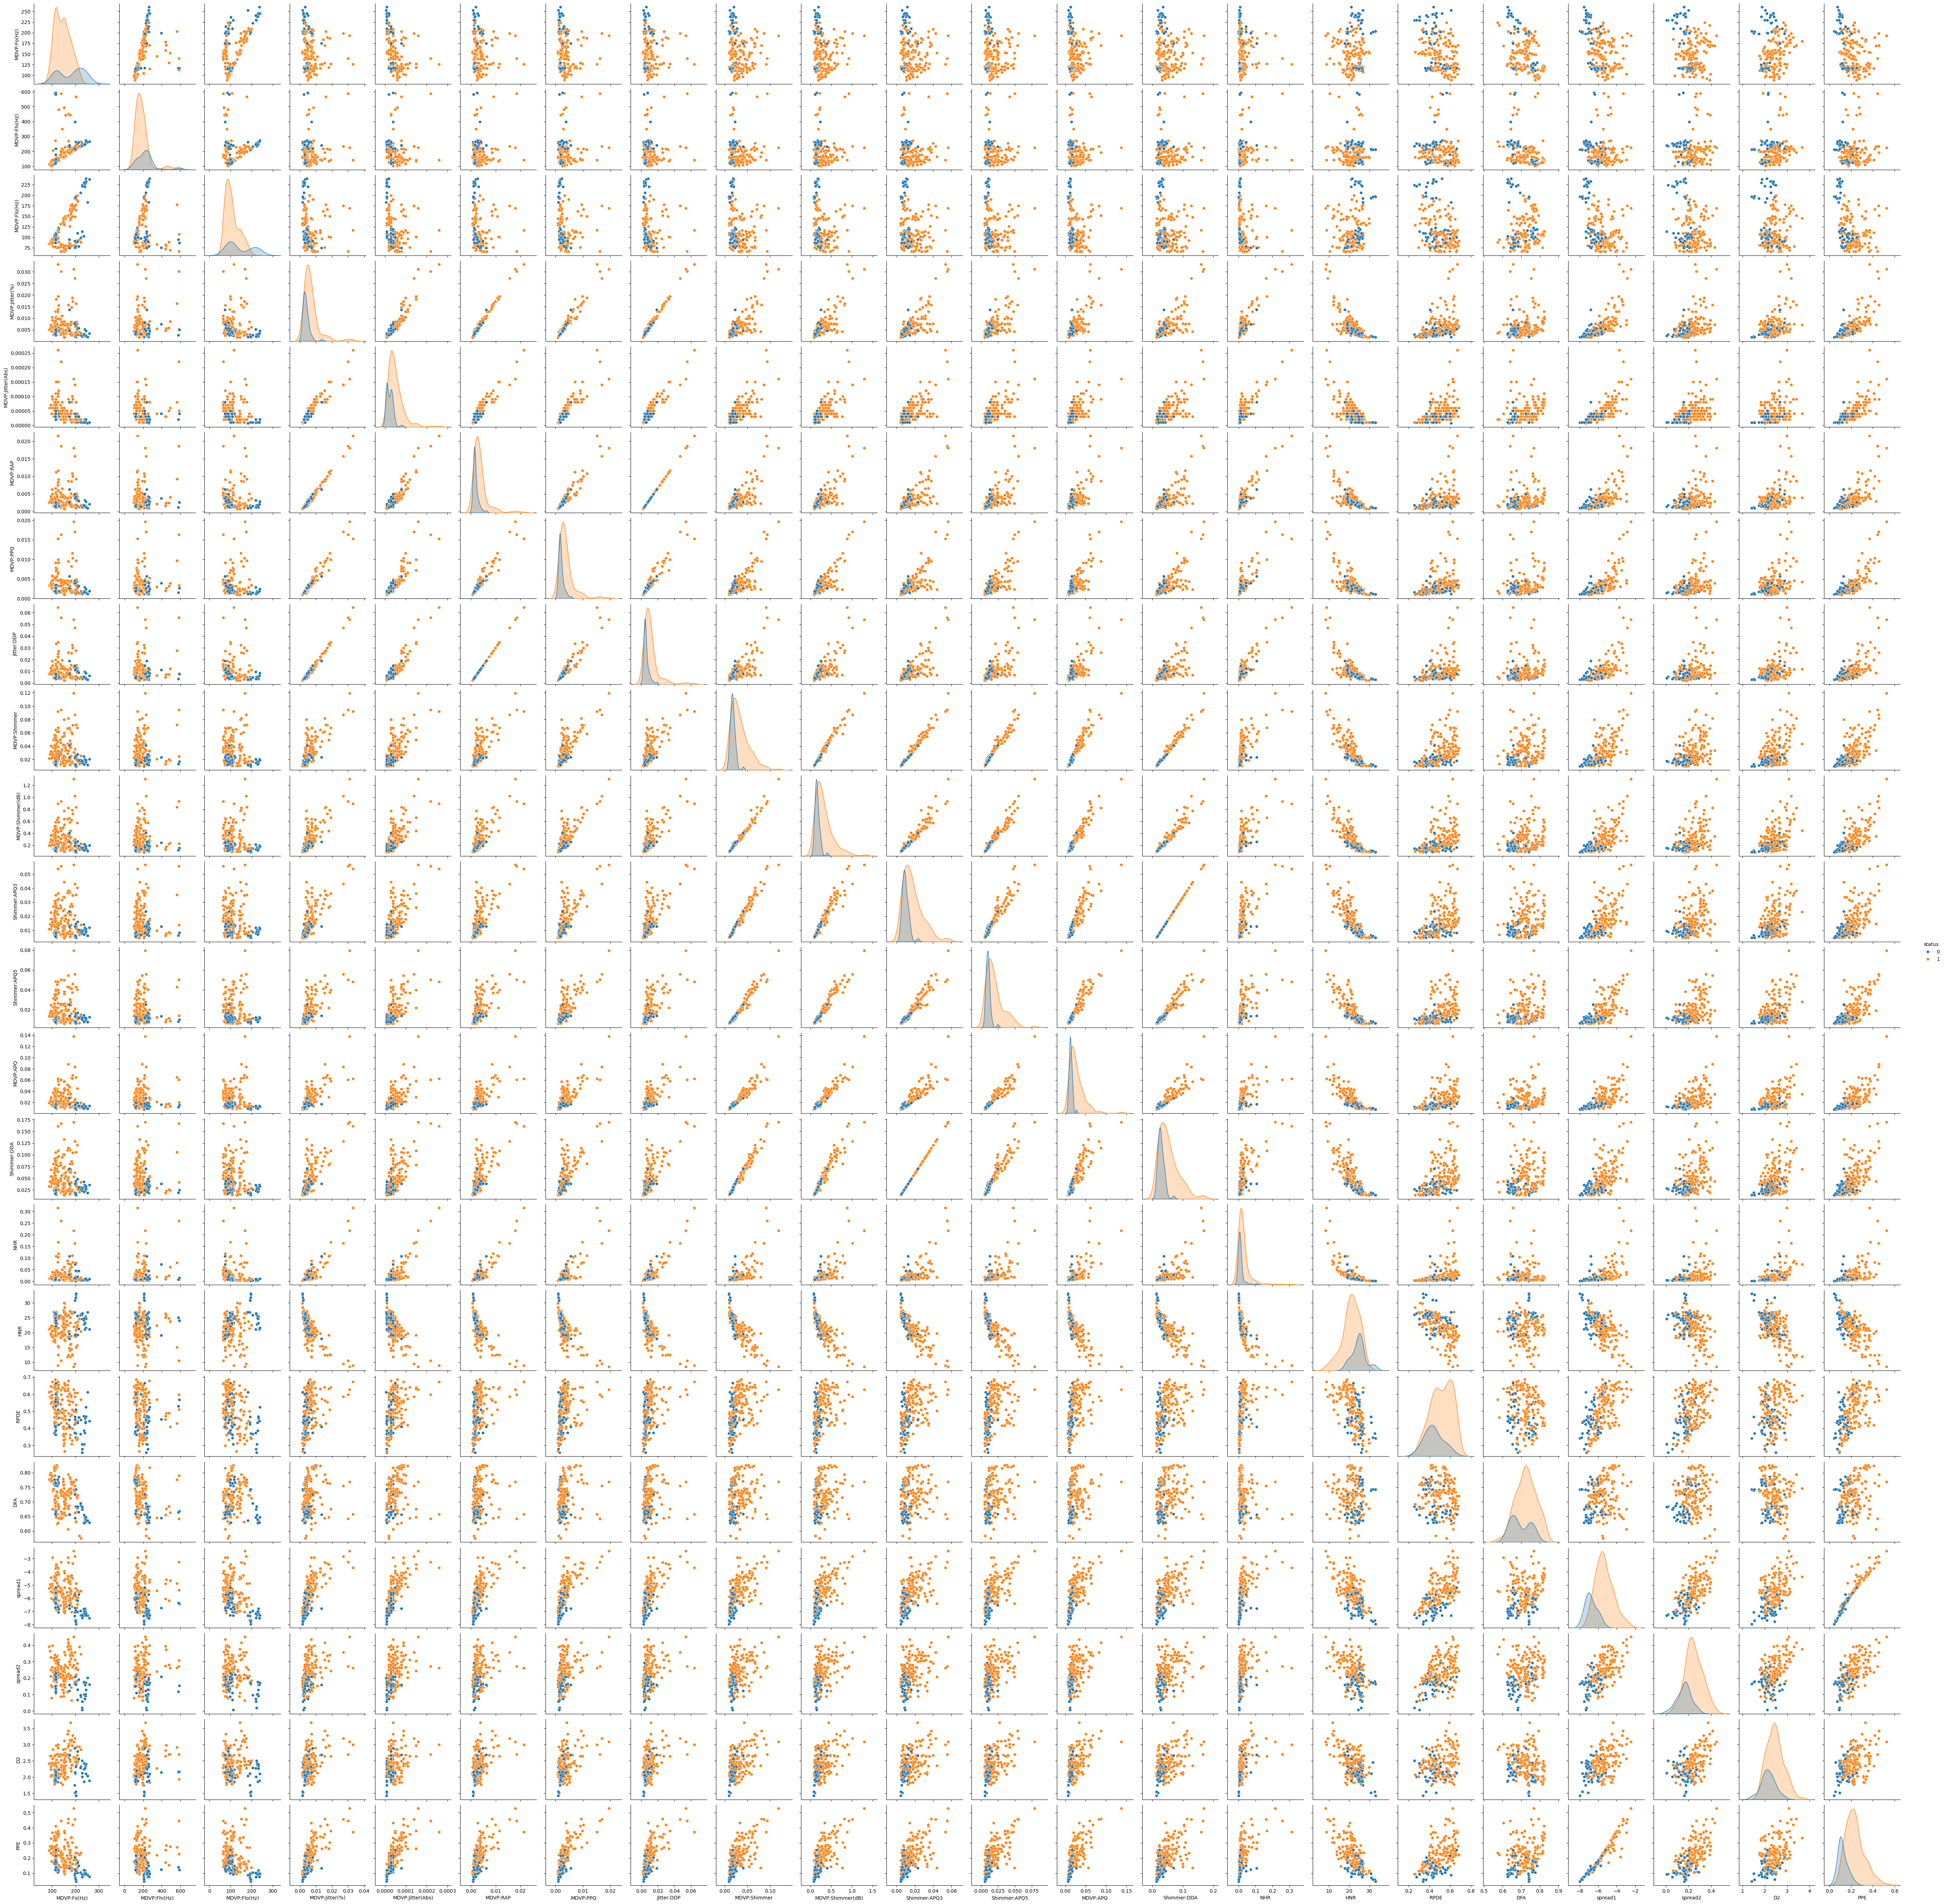

In [36]:
sns.pairplot(park_df,hue='status')

In [37]:
X=park_df.drop(columns=['status','name'],axis=1)
y=park_df['status']

In [38]:
X.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
0,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [39]:
y.head()

0    1
1    1
2    1
3    1
4    1
Name: status, dtype: int64

In [40]:
scaler=StandardScaler()

In [41]:
scaler.fit(X)

StandardScaler()

In [42]:
Standardize_data=scaler.transform(X)

In [43]:
X=Standardize_data
y=park_df['status']

In [44]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=40)

In [45]:
y_train.count()

156

In [46]:
y_train.value_counts()

status
1    116
0     40
Name: count, dtype: int64

In [47]:
y_test.value_counts()

status
1    31
0     8
Name: count, dtype: int64

In [48]:
X_train.shape,X_test.shape

((156, 22), (39, 22))

In [49]:
classifier=svm.SVC(kernel='linear')

In [50]:
classifier.fit(X_train,y_train)

SVC(kernel='linear')

In [51]:
X_train_prediction=classifier.predict(X_train)
accuracy=accuracy_score(X_train_prediction,y_train)
X_train_prediction=classifier.predict(X_test)
accuracy=accuracy_score(X_train_prediction,y_test)

In [52]:
accuracy

0.9230769230769231

In [53]:
input_data=(199.228,209.512,192.091,0.00241,0.00001,0.00134,0.00138,0.00402,0.1015,0.089,0.00504,0.00641,0.00762,0.01513,0.00167,30.94,0.432439,0.742055,-7.682587,0.173319,2.103106,0.068501)

input_data_as_numpy_array = np.asarray(input_data)

input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)
std_data = scaler.transform(input_data_reshaped)
print(std_data)
prediction=classifier.predict(std_data)
print(prediction)

if(prediction[0]==0):
  print('The person is not parkisons')
else:
  print('The person is parkisons affected')


[[ 1.09000041  0.13595811  1.74537973 -0.78798769 -0.97772886 -0.66429301
  -0.75088631 -0.66437228  3.81693387 -0.99420878 -1.04908214 -0.95625893
  -0.97386653 -1.04877063 -0.57490418  2.05101994 -0.63753683  0.43403373
  -1.83757049 -0.63938344 -0.72998488 -1.53580809]]
[0]
The person is not parkisons


c:\Users\asus\anaconda3\envs\py311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [54]:

import pickle

In [55]:
fileName="../Datasets/parkisons.sav"

In [56]:
pickle.dump(classifier,open(fileName,'wb'))

In [57]:
file=open(fileName,'rb')
loaded_model=pickle.load(file)

In [58]:
input_data=(199.228,209.512,192.091,0.00241,0.00001,0.00134,0.00138,0.00402,0.1015,0.089,0.00504,0.00641,0.00762,0.01513,0.00167,30.94,0.432439,0.742055,-7.682587,0.173319,2.103106,0.068501)

input_data_as_numpy_array = np.asarray(input_data)

input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)
std_data = scaler.transform(input_data_reshaped)
print(std_data)
prediction=loaded_model.predict(std_data)
print(prediction)

if(prediction[0]==0):
  print('The person is not parkisons')
else:
  print('The person is parkisons affected')


[[ 1.09000041  0.13595811  1.74537973 -0.78798769 -0.97772886 -0.66429301
  -0.75088631 -0.66437228  3.81693387 -0.99420878 -1.04908214 -0.95625893
  -0.97386653 -1.04877063 -0.57490418  2.05101994 -0.63753683  0.43403373
  -1.83757049 -0.63938344 -0.72998488 -1.53580809]]
[0]
The person is not parkisons


c:\Users\asus\anaconda3\envs\py311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
